In [1]:
# This is required to run multiple processes with JAX.
from multiprocessing import set_start_method
set_start_method('forkserver', force=True)

import os
os.environ['JAX_PLATFORMS'] = 'cpu'

# import os
# os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
# os.environ["XLA_FLAGS"] = f"--xla_gpu_cuda_data_dir={os.environ.get('CUDA_HOME', '')}"

In [2]:
from config import Config
cfg = Config.from_file("/nas/cee-water/cjgleason/ted/swot-ml/runs/manning/swot_vD.yml")
cfg.quiet = True
cfg.num_workers = 4

In [3]:
from data import get_dataloaders

dls = get_dataloaders(cfg)

In [4]:
from train import Trainer
cfg.log = True
trainer = Trainer(cfg, dls['train'], dls['validate'])
# trainer.start_training()

Model contains 31,640 parameters
Logging at /nas/cee-water/cjgleason/ted/swot-ml/runs/manning/swot_vD_20260512_144956


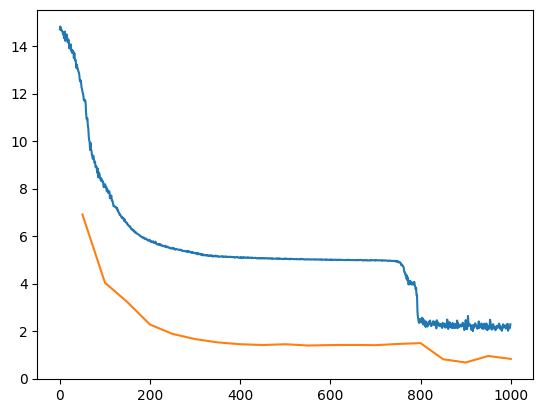

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

tl = pd.DataFrame(trainer.training_losses, index=['train_loss']).T
vl = pd.DataFrame(trainer.validation_losses, index=['val_loss']).T

plt.plot(tl)
plt.plot(vl)

In [9]:
for _, train_batch in dls['train']:
    break

for _, val_batch in dls['validate']:
    break
    
# batch = batch.to_jax()

In [15]:
import jax
key = jax.random.PRNGKey(0)

model = trainer.model
y_hat = model(train_batch, key)
y_hat

{'gage_q': {'A0': Array([[ 25.894876,  23.53803 ,  26.229399, ...,  25.985287,  23.473482,
           24.804739],
         [ 73.3698  ,  92.50243 ,  95.926834, ...,  87.19773 ,  84.66781 ,
           73.57548 ],
         [ 73.97094 ,  65.648544,  62.83458 , ...,  74.15693 ,  75.446075,
           74.53031 ],
         ...,
         [ 84.94211 ,  84.34456 ,  88.91437 , ...,  88.54152 ,  89.464584,
           95.459366],
         [608.943   , 486.80685 , 437.50156 , ..., 557.67285 , 561.13586 ,
          471.9791  ],
         [ 52.739464,  46.606052,  53.571053, ...,  56.965683,  59.58095 ,
           55.432667]], dtype=float32),
  'Q': Array([[[7.55053341e-01, 8.91206324e-01, 8.16825449e-01, ...,
           8.23020264e+02, 8.23020264e+02, 8.23020264e+02],
          [5.48787177e-01, 6.57884955e-01, 5.98200321e-01, ...,
           6.00766296e+02, 6.00766296e+02, 6.00766296e+02],
          [7.07461476e-01, 8.33371341e-01, 7.64598787e-01, ...,
           7.70720703e+02, 7.70720703e+02, 7.707

In [11]:
if hasattr(batch, 'node_mask'):
    data_mask = batch.node_mask
    if loss_name in ["nse", "spin_up_nse"]:
        # Expand the mask with a time dimension for broadcasting.
        data_mask = data_mask[jnp.newaxis, :]
elif hasattr(batch, 'd_mask'):
    data_mask = batch.d_mask
else:
    raise AttributeError(f"Cannot find mask attribute in data batch:\n{batch.keys()=}")

data_mask.shape

(16, 300)

In [12]:
def manning_nll(y, y_hat, mask, norm_fn, denorm_fn):
    y_hat_norm = norm_fn(y_hat['Q'])
    mu_q = jnp.mean(y_hat_norm, axis=1)  # (B, num_reaches)
    var_q = jnp.mean((y_hat_norm - mu_q[:, None, :]) ** 2, axis=1)
    std_q = jnp.sqrt(var_q + 1e-6)  # eps for numerical stability

    err = (y - mu_q) / std_q
    nll = jnp.log(std_q) + 0.5 * err**2

    valid = mask & jnp.isfinite(nll)
    return jnp.mean(nll, where=valid)

loss_fn = manning_nll

In [28]:
import jax.numpy as jnp
from functools import partial

for target_name, y_target in batch.y.items():
    # Skip targets the model didn't predict (or aren't in target_weights)
    if target_name not in y_hat:
        continue
    if cfg.step_kwargs.target_weights.get(target_name, 0.0) == 0.0:
        continue
    y_hat_target = y_hat[target_name]

    if y_target.ndim > data_mask.ndim:
        y_target = y_target[..., 0]

    valid_mask = ~jnp.isnan(y_target) & data_mask
    masked_y = jnp.where(valid_mask, y_target, 0)

    masked_y_hat = y_hat_target
    masked_y_hat['Q'] = jnp.where(valid_mask[:, None, :], y_hat_target['Q'], 0)

    target_norm_fn = partial(dls['train'].normalize, name=target_name)
    target_denorm_fn = partial(dls['train'].denormalize, name=target_name)

    loss = loss_fn(masked_y, masked_y_hat, valid_mask, target_norm_fn, target_denorm_fn)

In [30]:
y_hat_norm = target_norm_fn(masked_y_hat['Q'])
mu_q = jnp.mean(y_hat_norm, axis=1)  # (B, num_reaches)
var_q = jnp.mean((y_hat_norm - mu_q[:, None, :]) ** 2, axis=1)
std_q = jnp.sqrt(var_q + 1e-6)  # eps for numerical stability


In [35]:
w = batch.hws[..., 1]
s = batch.hws[..., 2]
mask = batch.d_mask

diagnostics = {
    "global_nan_present": jnp.any(jnp.isnan(batch.hws)),
    "global_inf_present": jnp.any(jnp.isinf(batch.hws)),
    "active_w_zero_or_negative": jnp.sum((w <= 0.0) & mask),
    "active_s_negative": jnp.sum((s < 0.0) & mask),
    "dead_sequences_all_masked": jnp.sum(jnp.sum(mask, axis=-1) == 0)
}
diagnostics

{'global_nan_present': Array(False, dtype=bool),
 'global_inf_present': Array(False, dtype=bool),
 'active_w_zero_or_negative': Array(0, dtype=int32),
 'active_s_negative': Array(43, dtype=int32),
 'dead_sequences_all_masked': Array(0, dtype=int32)}

In [42]:
import numpy as np

slopes = batch.hws
slopes = slopes[slopes>0]
np.min(slopes)

1.56844e-06

In [43]:
np.sqrt(0)

0.0

In [6]:
from models import make

cfg, model = make(cfg, dls['train'])

Model contains 31,640 parameters


In [8]:
pred = model(batch, key)


In [11]:
{k: v.shape for k, v in pred['gage_q'].items()}

{'A0': (16, 32), 'Q': (16, 32, 300), 'n': (16, 32)}

In [12]:
batch.d_mask.shape

(16, 300)

In [8]:
y = batch.y['gage_q']
y.shape

(16, 300)

In [30]:
mu_q.shape

(16, 300)

In [31]:
var_q.shape

(16, 300)

In [32]:
std_q.shape

(16, 300)

In [33]:
mask.shape

(16, 300, 1)

In [11]:
mask.shape

(16,)

In [15]:
import jax.numpy as jnp

y = batch.y['gage_q']
y_hat = pred['gage_q']
mask = batch.d_mask

y_hat_norm = dls['train'].dataset.normalize(y_hat['Q'], 'gage_q')

mu_q = jnp.mean(y_hat_norm, axis=1)  # (B, num_reaches)
var_q = jnp.mean((y_hat_norm - mu_q[:, None, :]) ** 2, axis=1)
std_q = jnp.sqrt(var_q + 1e-6)  # eps for numerical stability

err = (y - mu_q) / std_q
nll = jnp.log(std_q) + 0.5 * err**2

valid = mask & jnp.isfinite(nll)
jnp.mean(nll, where=valid)


Array(990.3536, dtype=float32)

In [17]:
y

Array([[-0.5489834 , -0.4478126 , -0.48755458, ...,         nan,
                nan,         nan],
       [-0.40072098, -0.4323611 , -0.46739185, ...,         nan,
                nan,         nan],
       [-0.6703276 , -0.6727974 , -0.7118593 , ...,         nan,
                nan,         nan],
       ...,
       [-0.69882196, -0.69882196, -0.67853236, ...,         nan,
                nan,         nan],
       [-0.75436383, -0.75436383, -0.75436383, ...,         nan,
                nan,         nan],
       [-0.0447558 , -0.02664608, -0.16955873, ...,         nan,
                nan,         nan]], dtype=float32)

In [10]:
mu_q

Array([[           nan, 1.52524605e+01, 6.00378609e+00, ...,
        1.26230518e+03, 1.26230518e+03, 1.26230518e+03],
       [4.49522695e+04, 5.83852812e+04, 5.73565078e+04, ...,
        5.59992969e+03, 5.59992969e+03, 5.59992969e+03],
       [4.53463715e+02, 2.89307495e+02, 2.58581848e+02, ...,
        8.04652637e+03, 8.04652637e+03, 8.04652637e+03],
       ...,
       [6.88542461e+00, 3.81154585e+00, 3.96717525e+00, ...,
        4.80959668e+03, 4.80959668e+03, 4.80959668e+03],
       [           nan, 8.16946983e+00, 5.54468155e+01, ...,
        1.07205117e+04, 1.07205117e+04, 1.07205117e+04],
       [7.42194796e+00, 1.00519657e+01, 5.14443827e+00, ...,
        1.98551660e+03, 1.98551660e+03, 1.98551660e+03]], dtype=float32)

In [37]:
node_mask = batch.d_mask[...,0]

valid_mask = ~jnp.isnan(y) & node_mask

valid_mask.shape

(16, 300)

In [25]:
import equinox as eqx
import jax
import jax.numpy as jnp
from jaxtyping import Array, PRNGKeyArray
from jax.scipy.special import logsumexp

from models.base_model import BaseModel
from data import TabularBatch

from models import set_model_data_args

class MixtureHead(eqx.Module):
    net: eqx.nn.MLP
    num_components: int

    def __init__(self, in_size, hidden_size, depth, num_components, *, key):
        self.num_components = num_components
        # Outputs: num_components * (weight_logit, mean, log_std)
        self.net = eqx.nn.MLP(
            in_size=in_size, out_size=num_components * 3, width_size=hidden_size, depth=depth, key=key
        )

    def __call__(self, x):
        out = self.net(x)
        logits, means, log_stds = jnp.split(out, 3, axis=-1)
        log_weights = jax.nn.log_softmax(logits, axis=-1)  # (K,)
        log_stds = jnp.clip(log_stds, -6, 0)  # numerical stability
        return log_weights, means, log_stds

    def sample(self, x, key):
        log_weights, means, log_stds = self(x)
        k1, k2 = jax.random.split(key)
        # Gumbel-max trick to sample component
        component = jnp.argmax(log_weights + jax.random.gumbel(k1, shape=log_weights.shape))
        mean = means[component]
        std = jnp.exp(log_stds[component])
        return mean + std * jax.random.normal(k2, shape=mean.shape)

    def mean(self, x):
        """E[x] = sum_k w_k * mu_k"""
        log_weights, means, _ = self(x)
        return jnp.sum(jnp.exp(log_weights) * means)

    def log_prob(self, x, value):
        """Log likelihood of a scalar value under the mixture."""
        log_weights, means, log_stds = self(x)
        stds = jnp.exp(log_stds)
        log_component_probs = (
            -0.5 * ((value - means) / stds) ** 2 - log_stds - 0.5 * jnp.log(2 * jnp.pi)
        )
        return logsumexp(log_weights + log_component_probs)


class ManningNet(BaseModel):
    A0_head: MixtureHead
    n_head: MixtureHead
    num_components: int
    num_samples: int

    def __init__(
        self,
        *,
        target: list[str],
        dynamic_size: int,
        static_size: int,
        hidden_size: int,
        depth: int,
        num_components: int,
        num_samples: int,
        seed: int,
        **kwargs # Capture some defaults that we don't need. 
    ):
        key = jax.random.PRNGKey(seed)
        k1, k2, k3 = jax.random.split(key, 3)
        super().__init__(hidden_size, target, "none", key=k1)

        
        self.num_components = num_components
        self.num_samples = num_samples
        self.A0_head = MixtureHead(dynamic_size + static_size, hidden_size, depth, num_components, key=k2)
        self.n_head = MixtureHead(dynamic_size + static_size, hidden_size, depth, num_components, key=k3)

    def __call__(self, batch: TabularBatch, key: PRNGKeyArray):
        def get_gmm_params(x_temporal):
            feat = jnp.concat([x_temporal, batch.x_s])
            return self.A0_head(feat), self.n_head(feat)

        all_A0_gmm, all_n_gmm = jax.vmap(get_gmm_params)(batch.x_d)

        k1, k2 = jax.random.split(key)
        A0_samples = self._sample_gmm_all(all_A0_gmm, k1)  # (T, S)
        n_samples = self._sample_gmm_all(all_n_gmm, k2)  # (T, S)

        # If all timesteps masked, mean is undefined — default to 0
        n_valid = jnp.sum(batch.d_mask)
        mask = batch.d_mask#[:, None]

        A0_latent = jnp.where(
            n_valid > 0,
            jnp.sum(A0_samples * mask, axis=0) / jnp.maximum(n_valid, 1),
            jnp.zeros(self.num_samples),
        )
        n_latent = jnp.where(
            n_valid > 0,
            jnp.sum(n_samples * mask, axis=0) / jnp.maximum(n_valid, 1),
            jnp.zeros(self.num_samples),
        )

        dh, w, s = batch.hws[:, 0], batch.hws[:, 1], batch.hws[:, 2]
        dA = w * dh
        avg_w = jnp.sum(w * batch.d_mask) / jnp.maximum(n_valid, 1)  # safe masked mean
        min_dA = jnp.min(dA)  # can be -inf if dA has bad values
        min_dA = jnp.where(jnp.isfinite(min_dA), min_dA, 0.0)

        def manning(a0_latent, n_latent):
            # Clamp before any nonlinear transform
            a0_latent = jnp.clip(a0_latent, -5.0, 5.0)
            n_latent = jnp.clip(n_latent, -5.0, 5.0)
            A0 = (jax.nn.softplus(a0_latent) * avg_w) + 1e-6
            A = A0 + dA
            # Guard negative areas before fractional power
            A = jnp.clip(A, 1e-6, None)
            n = 0.3 + 0.299 * jnp.tanh(n_latent)
            Q = (1 / n) * jnp.power(A, 5 / 3) * jnp.power(w, -2 / 3) * jnp.sqrt(s)
            # Final guard — don't let Q explode into the loss
            Q = jnp.clip(Q, 0.0, 1e8)
            return Q, A0, n

        Q_samples, A0_out, n_out = jax.vmap(manning)(A0_latent, n_latent)

        out = {
            target
        return Q_samples, A0_out, n_out

    def _sample_gmm_all(self, gmm_params, key):
        """Sample S values from each of T GMMs. Returns (T, S)."""
        log_weights, means, log_stds = gmm_params  # each (T, K)
        T = means.shape[0]
        keys = jax.random.split(key, T)

        def sample_one(lw, mu, ls, k):
            # Draw S samples from a single K-component GMM
            k1, k2 = jax.random.split(k)
            # (S,) component indices via Gumbel-max
            gumbels = jax.random.gumbel(k1, shape=(self.num_samples, self.num_components))
            components = jnp.argmax(lw[None, :] + gumbels, axis=-1)  # (S,)
            # Gather means and stds for selected components
            sel_mu = mu[components]  # (S,)
            sel_std = jnp.exp(ls[components])  # (S,)
            samples = sel_mu + sel_std * jax.random.normal(k2, shape=(self.num_samples,))
            # Clamp latent samples to a sane range before physics transforms
            return jnp.clip(samples, -5.0, 5.0)

        return jax.vmap(sample_one)(log_weights, means, log_stds, keys)  # (T, S)


def probabilistic_loss(model, x_d, d_mask, x_s, hws, y, norm_fn, key):
    keys = jax.random.split(key, x_d.shape[0])
    Q_samples, _, _ = jax.vmap(model)(x_d, d_mask, x_s, hws, keys)
    # Q_samples: (B, S, num_reaches)

    y_hat = jax.vmap(jax.vmap(norm_fn))(Q_samples)  # (B, S, num_reaches)

    mu_q = jnp.mean(y_hat, axis=1)  # (B, num_reaches)
    var_q = jnp.mean((y_hat - mu_q[:, None, :]) ** 2, axis=1)
    std_q = jnp.sqrt(var_q + 1e-6)  # fused for numerical stability

    err = (y - mu_q) / std_q
    nll = jnp.log(std_q) + 0.5 * err**2

    valid = d_mask & jnp.isfinite(nll)
    return jnp.sum(jnp.where(valid, nll, 0.0)) / jnp.maximum(jnp.sum(valid), 1)


model_cfg = set_model_data_args(cfg, dls['train'].dataset)
model = ManningNet(**model_cfg.model_args.as_kwargs())

In [23]:
batch.hws.shape

(32, 300, 3)

In [6]:
sample = dls['train'].dataset[0]

sample['x_d'].shape

(300, 24)

In [19]:
sample['x_s'].shape[-1]

15